# Diffusivity comparison between studies

Goal here is to compare the distribution of diffusivity estimates between my and Espe's estimates, and other papers using different methods. Cole, Groeskamp, Sevellec, Roach, etc

In [1]:
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.colors as colors
from matplotlib.cm import ScalarMappable
import cartopy.crs as ccrs
import cmocean.cm as cmo
import h5py

# Load Datasets

In [33]:
# my dataset
ds_pbar_grid = xr.open_dataset('/swot/SUM05/amf2288/ds_pbar_grid_var.nc')
ds_pbar_grad = xr.open_dataset('/swot/SUM05/amf2288/ds_pbar_grad_diff.nc')
ds_pbar_grid = ds_pbar_grid.assign_coords(LON_left = ds_pbar_grad.LON_left,LAT_left = ds_pbar_grad.LAT_left)
ds_amf = xr.merge([ds_pbar_grid, ds_pbar_grad.drop_vars({'DENSITY'})])

In [34]:
# espe's dataset
ds_eb = xr.open_dataset("/swot/SUM05/amf2288/argo_mixing/global_datasets_20261116/global_binned_3deg.nc", engine="netcdf4")

In [35]:
# Cole et al. (2015): promote the physical lon/lat variables to coordinates.
ds_Cole = xr.open_dataset('/swot/SUM05/amf2288/diff_comp/Cole2015_3deg.nc')
ds_Cole = ds_Cole.set_coords(['longitude', 'latitude']).swap_dims(
    {'lon': 'longitude', 'lat': 'latitude'}
)
ds_Cole = ds_Cole.assign_coords(
    longitude=(ds_Cole.longitude + 180) % 360 - 180
).sortby('longitude')

In [36]:
# Groeskamp et al. (2020): this MATLAB v7.3 file uses HDF5, not NetCDF.
# K_WOA is stored by h5py in (depth, latitude, longitude) order.
groeskamp_path = '/swot/SUM05/amf2288/diff_comp/Groeskamp2020_K.mat'
with h5py.File(groeskamp_path, 'r') as mat:
    woa = mat['WOA18_K']
    ds_Groeskamp = xr.Dataset(
        data_vars={
            'K_WOA': (
                ('depth', 'latitude', 'longitude'), woa['K_WOA'][()],
                {'units': 'm2 s-1', 'long_name': 'Groeskamp 2020 eddy diffusivity'},
            ),
        },
        coords={
            'depth': ('depth', woa['z'][()].ravel(), {'units': 'm', 'positive': 'down'}),
            'latitude': ('latitude', woa['y'][()].ravel(), {'units': 'degrees_north'}),
            'longitude': ('longitude', woa['x'][()].ravel(), {'units': 'degrees_east'}),
        },
        attrs={'source': groeskamp_path, 'matlab_variable': 'WOA18_K.K_WOA'},
    )
ds_Groeskamp = ds_Groeskamp.assign_coords(
    longitude=(ds_Groeskamp.longitude + 180) % 360 - 180
).sortby('longitude')

# Compare diffusivities

Use the same eight target levels, nearest-level selection, Plate Carrée maps,
`cmo.dense_r` colormap, and logarithmic limits as `comp_diffusivity.ipynb`.
Each figure has studies in rows and target levels in columns.

- **AMF:** recalculate `K_e_CT` and `K_e_SA` with the same original, unclipped
  gradients and vertically filled `K_rho_filt_p.nc` as the reference notebook.
- **Espe:** use `KisoT_pressure` and `KisoS_pressure` (pooled isopycnal estimates
  already mapped to pressure).
- **Cole 2015:** use the supplied `diffusivity` field.
- **Groeskamp 2020:** use `WOA18_K.K_WOA` from `Groeskamp2020_K.mat`.

AMF and Espe are selected in **dbar**; Cole and Groeskamp in **meters**.
These are approximate vertical comparisons using the same numerical targets,
without converting pressure to depth. The table and panel titles show the actual
nearest levels. All maps retain their native horizontal grids (no regridding).
Cole and Groeskamp each supply one diffusivity field, repeated in both figures;
the CT/SA distinction applies only to AMF and Espe.
Only finite, positive estimates can appear on the log scale. Empty levels are
labeled explicitly; in particular, Espe's nearest level to 1900 is 1925 dbar.

In [37]:
# Edit (minimum, maximum) colorbar limits in m² s⁻¹; limits must be positive.
# Each tracer uses one log scale shared by all four studies and all levels.
CT_DIFFUSIVITY_LIMITS = (1e1, 1e5)
SA_DIFFUSIVITY_LIMITS = (1e1, 1e5)
DIFFUSIVITY_CMAP = cmo.dense_r
depths = [200, 500, 750, 1000, 1250, 1500, 1700, 1900]

In [38]:
# Recalculate the canonical fields on every plot run, including in an old kernel.
# This uses the original gradient components, with no minimum gradient floor.
amf_krho = (
    xr.open_dataarray('/swot/SUM05/amf2288/K_rho_filt_p.nc')
    .drop_vars('Z').rename({'PRESSURE': 'PRESSURE_mean'})
    .bfill('PRESSURE_mean').ffill('PRESSURE_mean')
)
for tracer in ['CT', 'SA']:
    gradient_squared = ds_amf[f'd{tracer}_m_dx']**2 + ds_amf[f'd{tracer}_m_dy']**2
    denominator = gradient_squared.where(np.isfinite(gradient_squared) & (gradient_squared > 0))
    diffusivity = amf_krho * ds_amf[f'{tracer}_e_var'] / denominator
    ds_amf[f'K_e_{tracer}'] = diffusivity.where(np.isfinite(diffusivity))
    ds_amf[f'K_e_{tracer}'].attrs = {
        'units': 'm2 s-1',
        'long_name': f'Eddy diffusivity from {tracer}, using unclipped horizontal gradients',
        'formula': f'K_rho_p * {tracer}_e_var / (d{tracer}_m_dx**2 + d{tracer}_m_dy**2)',
        'gradient_floor': 'none; zero and nonfinite denominators are masked',
    }
    # Keep the earlier alias synchronized with the canonical field.
    ds_amf[f'K_e_{tracer}_unclipped'] = ds_amf[f'K_e_{tracer}']

In [39]:
# Show the actual levels used, including each study's native vertical units.
selected_levels = pd.DataFrame({
    'Target level': depths,
    'AMF [dbar]': ds_amf.PRESSURE_mean.sel(PRESSURE_mean=depths, method='nearest').values,
    'Espe [dbar]': ds_eb.pressure_bin.sel(pressure_bin=depths, method='nearest').values,
    'Cole 2015 [m]': ds_Cole.depth.sel(depth=depths, method='nearest').values,
    'Groeskamp 2020 [m]': ds_Groeskamp.depth.sel(depth=depths, method='nearest').values,
})
selected_levels

,Target level,AMF [dbar],Espe [dbar],Cole 2015 [m],Groeskamp 2020 [m]
0,200,200,225.0,200.0,200.0
1,500,500,525.0,500.0,500.0
2,750,750,775.0,760.0,750.0
3,1000,1000,1025.0,1000.0,1000.0
4,1250,1250,1275.0,1260.0,1250.0
5,1500,1500,1525.0,1500.0,1500.0
6,1700,1700,1725.0,1700.0,1700.0
7,1900,1900,1925.0,1900.0,1900.0


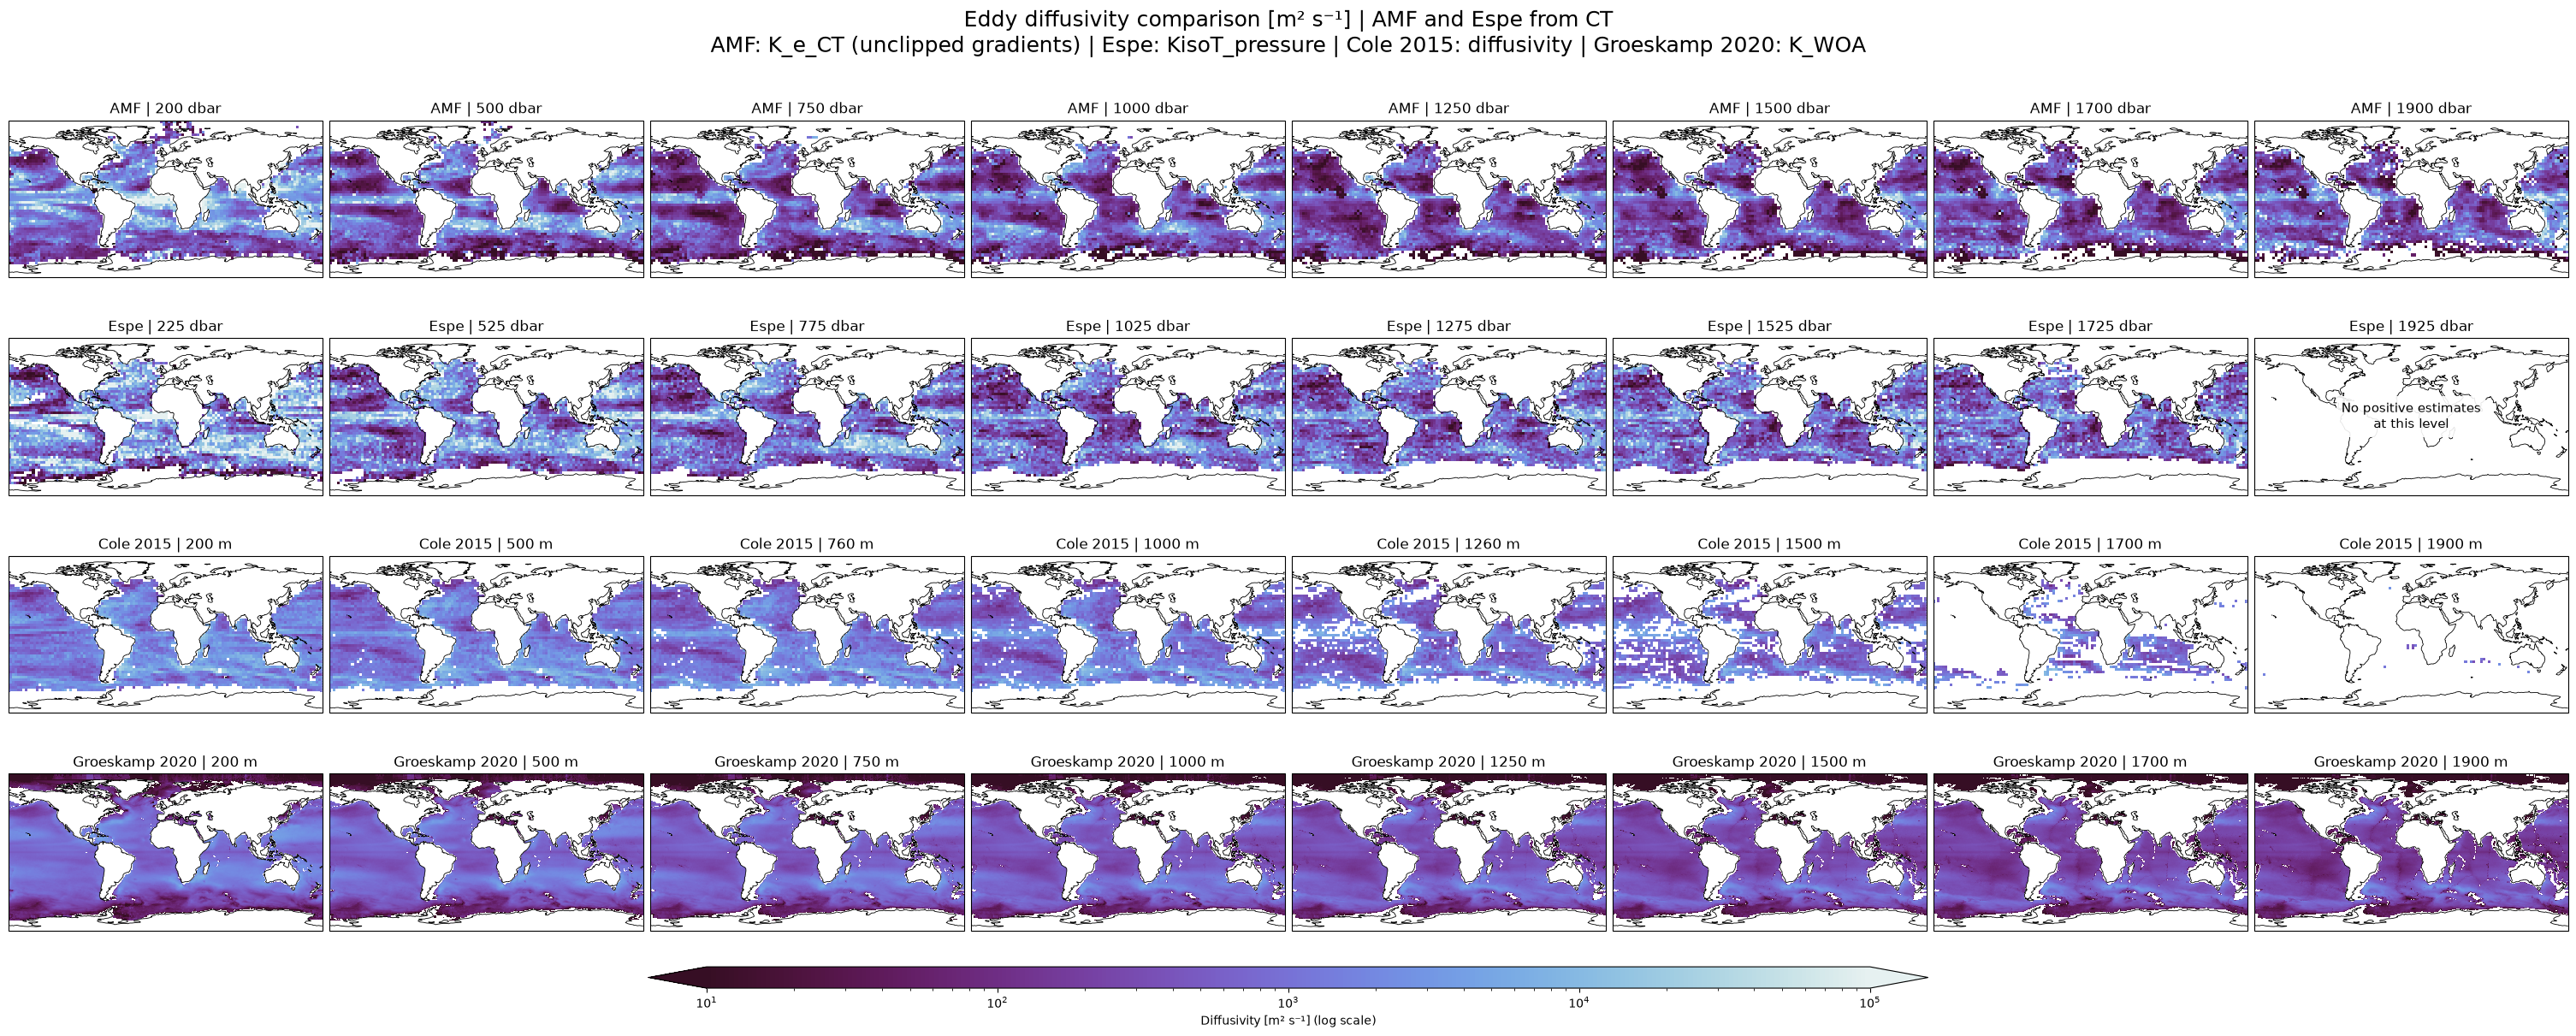

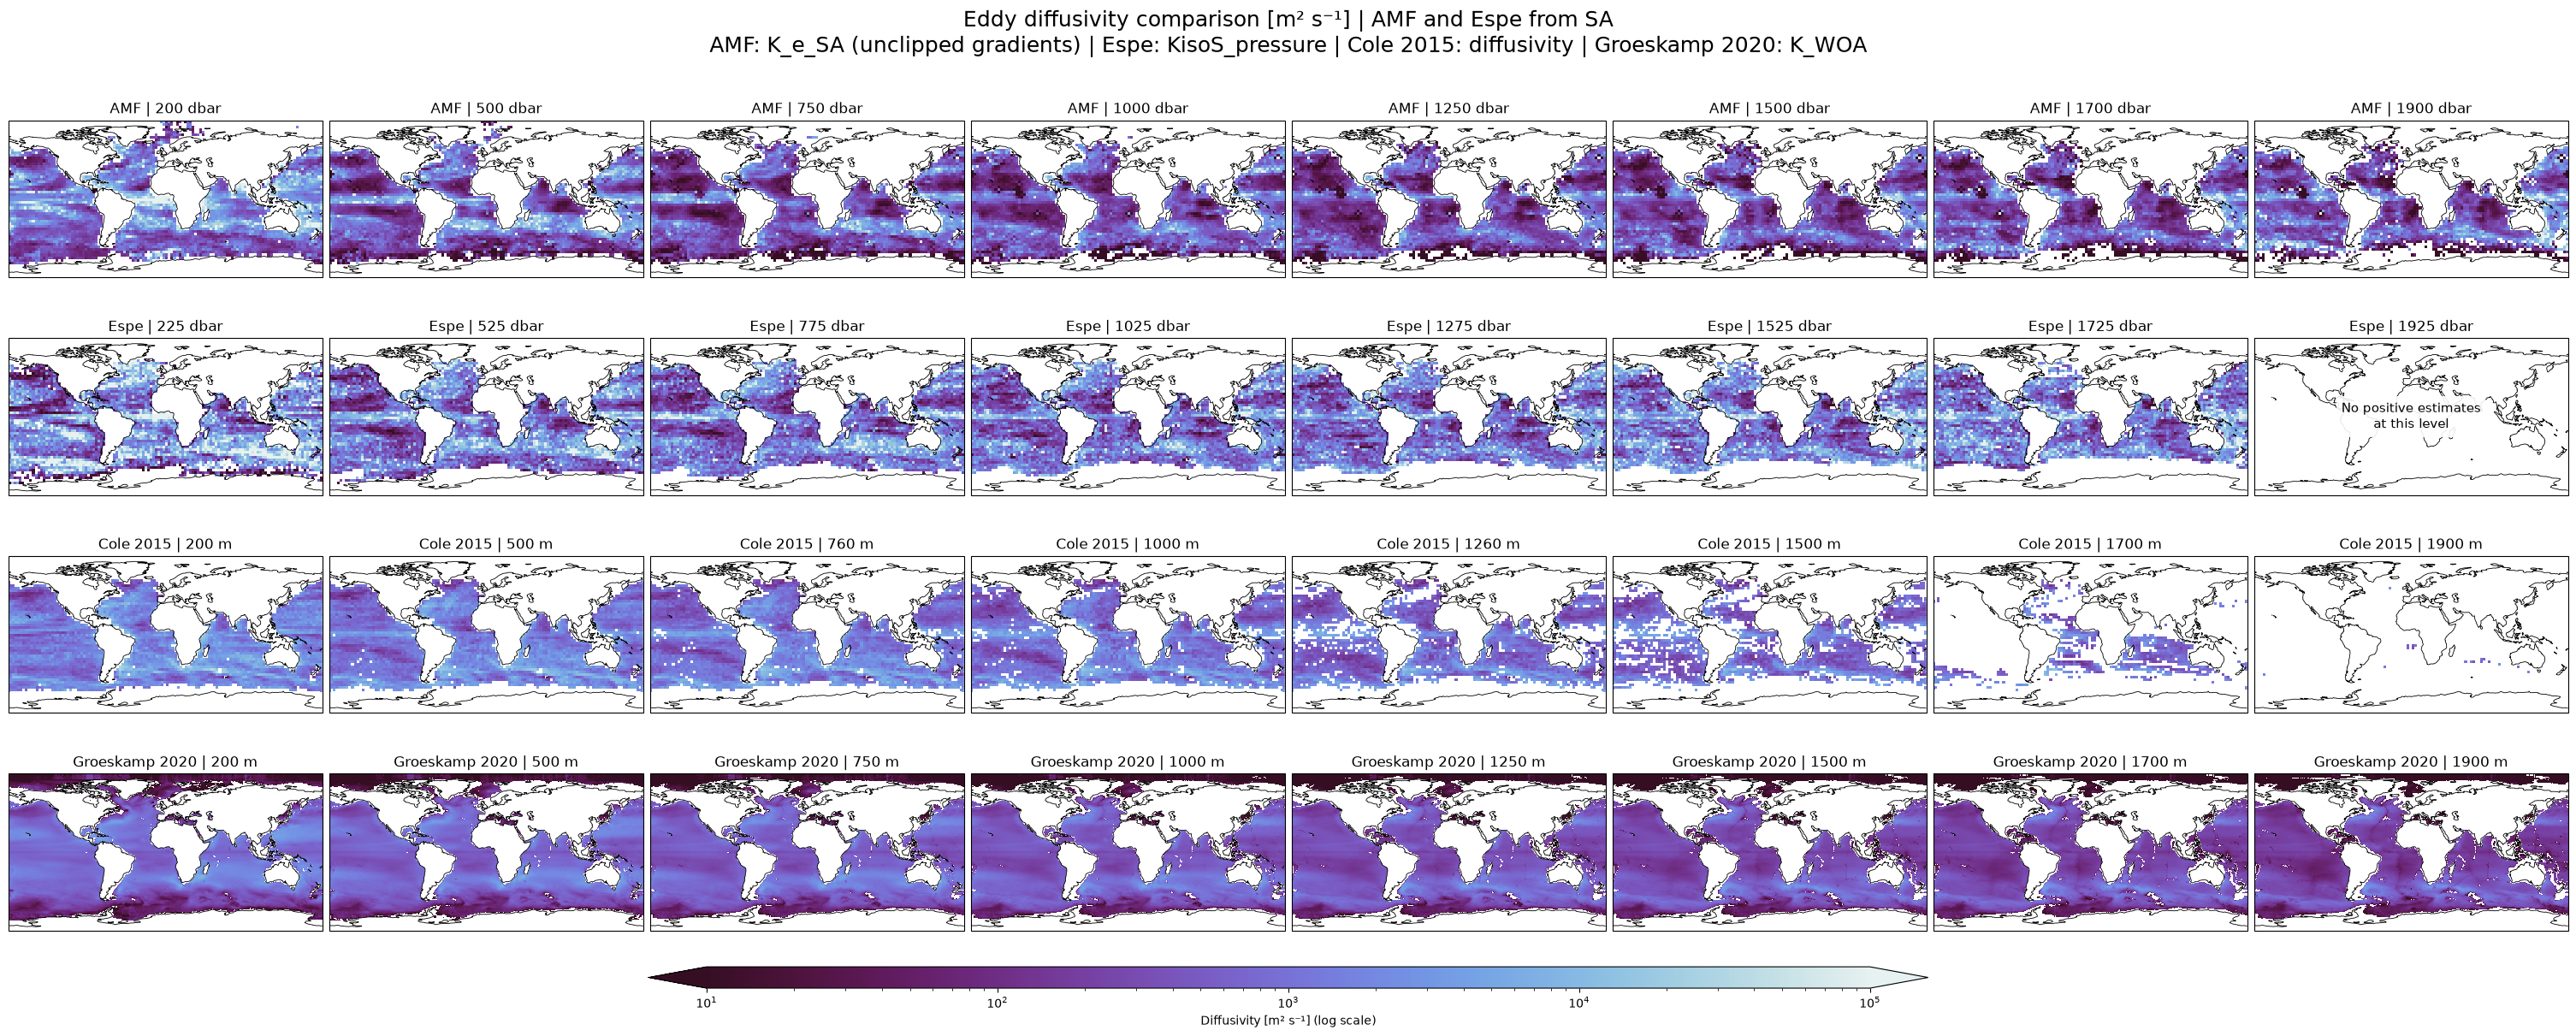

In [40]:
# One 4 × 8 comparison for CT, and one for SA.
# Published Cole/Groeskamp fields are the same reference rows in both figures.
# Close only this cell's earlier figures when rerunning it.
for previous_figure in globals().get('diffusivity_figures', {}).values():
    plt.close(previous_figure)
diffusivity_figures = {}
diffusivity_axes = {}

for tracer, amf_name, espe_name, limits in [
    ('CT', 'K_e_CT', 'KisoT_pressure', CT_DIFFUSIVITY_LIMITS),
    ('SA', 'K_e_SA', 'KisoS_pressure', SA_DIFFUSIVITY_LIMITS),
]:
    if not (0 < limits[0] < limits[1]):
        raise ValueError(f'{tracer} color limits must satisfy 0 < minimum < maximum.')
    diffusivity_norm = colors.LogNorm(vmin=limits[0], vmax=limits[1])
    diffusivity_ticks = np.geomspace(*limits, 5)
    studies = [
        ('AMF', ds_amf[amf_name], 'PRESSURE_mean', 'dbar', 'LON', 'LAT'),
        ('Espe', ds_eb[espe_name], 'pressure_bin', 'dbar', 'longitude', 'latitude'),
        ('Cole 2015', ds_Cole.diffusivity, 'depth', 'm', 'longitude', 'latitude'),
        ('Groeskamp 2020', ds_Groeskamp.K_WOA, 'depth', 'm', 'longitude', 'latitude'),
    ]
    fig, axes = plt.subplots(
        len(studies), len(depths), figsize=(30, 12), squeeze=False,
        subplot_kw={'projection': ccrs.PlateCarree()},
        constrained_layout=True,
    )
    fig.suptitle(
        f'Eddy diffusivity comparison [m² s⁻¹] | AMF and Espe from {tracer}\n'
        f'AMF: {amf_name} (unclipped gradients) | Espe: {espe_name} | '
        'Cole 2015: diffusivity | Groeskamp 2020: K_WOA',
        fontsize=18,
    )
    for row, (study, estimates, vertical, unit, lon, lat) in enumerate(studies):
        for col, depth in enumerate(depths):
            ax = axes[row, col]
            field = estimates.sel({vertical: depth}, method='nearest')
            actual_level = float(field[vertical])
            # Preserve the source values; mask only the field being plotted.
            field = field.where(np.isfinite(field) & (field > 0))
            if bool(field.notnull().any()):
                field.plot.pcolormesh(
                    ax=ax, x=lon, y=lat, transform=ccrs.PlateCarree(),
                    cmap=DIFFUSIVITY_CMAP, norm=diffusivity_norm, add_colorbar=False,
                )
            else:
                ax.text(
                    0.5, 0.5, 'No positive estimates\nat this level',
                    transform=ax.transAxes, ha='center', va='center', fontsize=11,
                    bbox={'facecolor': 'white', 'alpha': 0.9, 'edgecolor': 'none'},
                    zorder=5,
                )
            ax.set_global()
            ax.coastlines(resolution='110m', linewidth=0.6)
            ax.set_title(f'{study} | {actual_level:g} {unit}', fontsize=12)

    fig.colorbar(
        ScalarMappable(norm=diffusivity_norm, cmap=DIFFUSIVITY_CMAP),
        ax=axes.ravel().tolist(), orientation='horizontal',
        fraction=0.04, pad=0.04, shrink=0.5, aspect=60,
        ticks=diffusivity_ticks, extend='both',
        label='Diffusivity [m² s⁻¹] (log scale)',
    )
    diffusivity_figures[tracer] = fig
    diffusivity_axes[tracer] = axes

plt.show()

## Distributions on the same depth surfaces

Two figures show **CT** and **SA**, each with one histogram subplot per target
level in `histogram_depths` (the map levels with **1900 omitted**). The same
four fields and nearest native levels used in the maps are selected here; legends report the actual level and the number of
finite, positive cells (`n`). Cole and Groeskamp are repeated reference estimates
in both figures.

All studies, depths, and tracers share logarithmically spaced bins covering the
full finite, positive data range. **`CT_HISTOGRAM_XLIM` and `SA_HISTOGRAM_XLIM`**
near the top of the notebook control the visible range for each figure. These
limits zoom the axes without changing the bins or renormalizing the percentages.
The y-axis is **percentage of a study's finite, positive grid cells per bin**;
each full histogram sums to 100%, including bins outside the visible range. Each study uses its own native spatial
coverage with equal weight per grid cell. This normalization accounts for the
different numbers of grid cells; it does not area-weight or restrict studies to
a common spatial footprint. Empty distributions are labeled in the legend.

In [41]:
# Ten equal-width bins per decade (0.1 dex); shared across both figures.
HISTOGRAM_BINS_PER_DECADE = 10
HISTOGRAM_COLORS = {
    'AMF': 'tab:red',
    'Espe': 'tab:orange',
    'Cole 2015': 'tab:blue',
    'Groeskamp 2020': 'tab:green',
}

In [44]:
# Histogram x-axis limits (minimum, maximum), in m² s⁻¹.
# Edit these, then rerun this cell and the histogram plotting cell.
CT_HISTOGRAM_XLIM = (1e0, 1e6)
SA_HISTOGRAM_XLIM = (1e0, 1e6)
# These zoom the display; percentages still use all finite, positive cells.

In [45]:
# Use the same nearest-level fields as the maps, omitting 1900 in histograms.
histogram_depths = [depth for depth in depths if depth != 1900]
histogram_samples = {}
for tracer, amf_name, espe_name in [
    ('CT', 'K_e_CT', 'KisoT_pressure'),
    ('SA', 'K_e_SA', 'KisoS_pressure'),
]:
    for study, estimates, vertical, unit in [
        ('AMF', ds_amf[amf_name], 'PRESSURE_mean', 'dbar'),
        ('Espe', ds_eb[espe_name], 'pressure_bin', 'dbar'),
        ('Cole 2015', ds_Cole.diffusivity, 'depth', 'm'),
        ('Groeskamp 2020', ds_Groeskamp.K_WOA, 'depth', 'm'),
    ]:
        for depth in histogram_depths:
            field = estimates.sel({vertical: depth}, method='nearest')
            values = field.values.ravel()
            histogram_samples[tracer, study, depth] = {
                'values': values[np.isfinite(values) & (values > 0)],
                'level': float(field[vertical]),
                'unit': unit,
            }

# Include the tails instead of truncating to the map colorbar limits.
nonempty_samples = [sample['values'] for sample in histogram_samples.values()
                    if sample['values'].size]
if not nonempty_samples:
    raise ValueError('No finite, positive diffusivities at the selected levels.')
log_min = np.floor(np.log10(min(values.min() for values in nonempty_samples)))
log_max = np.ceil(np.log10(max(values.max() for values in nonempty_samples)))
log_max = max(log_max, log_min + 1)
histogram_bins = np.logspace(
    log_min, log_max, int((log_max - log_min) * HISTOGRAM_BINS_PER_DECADE) + 1,
)

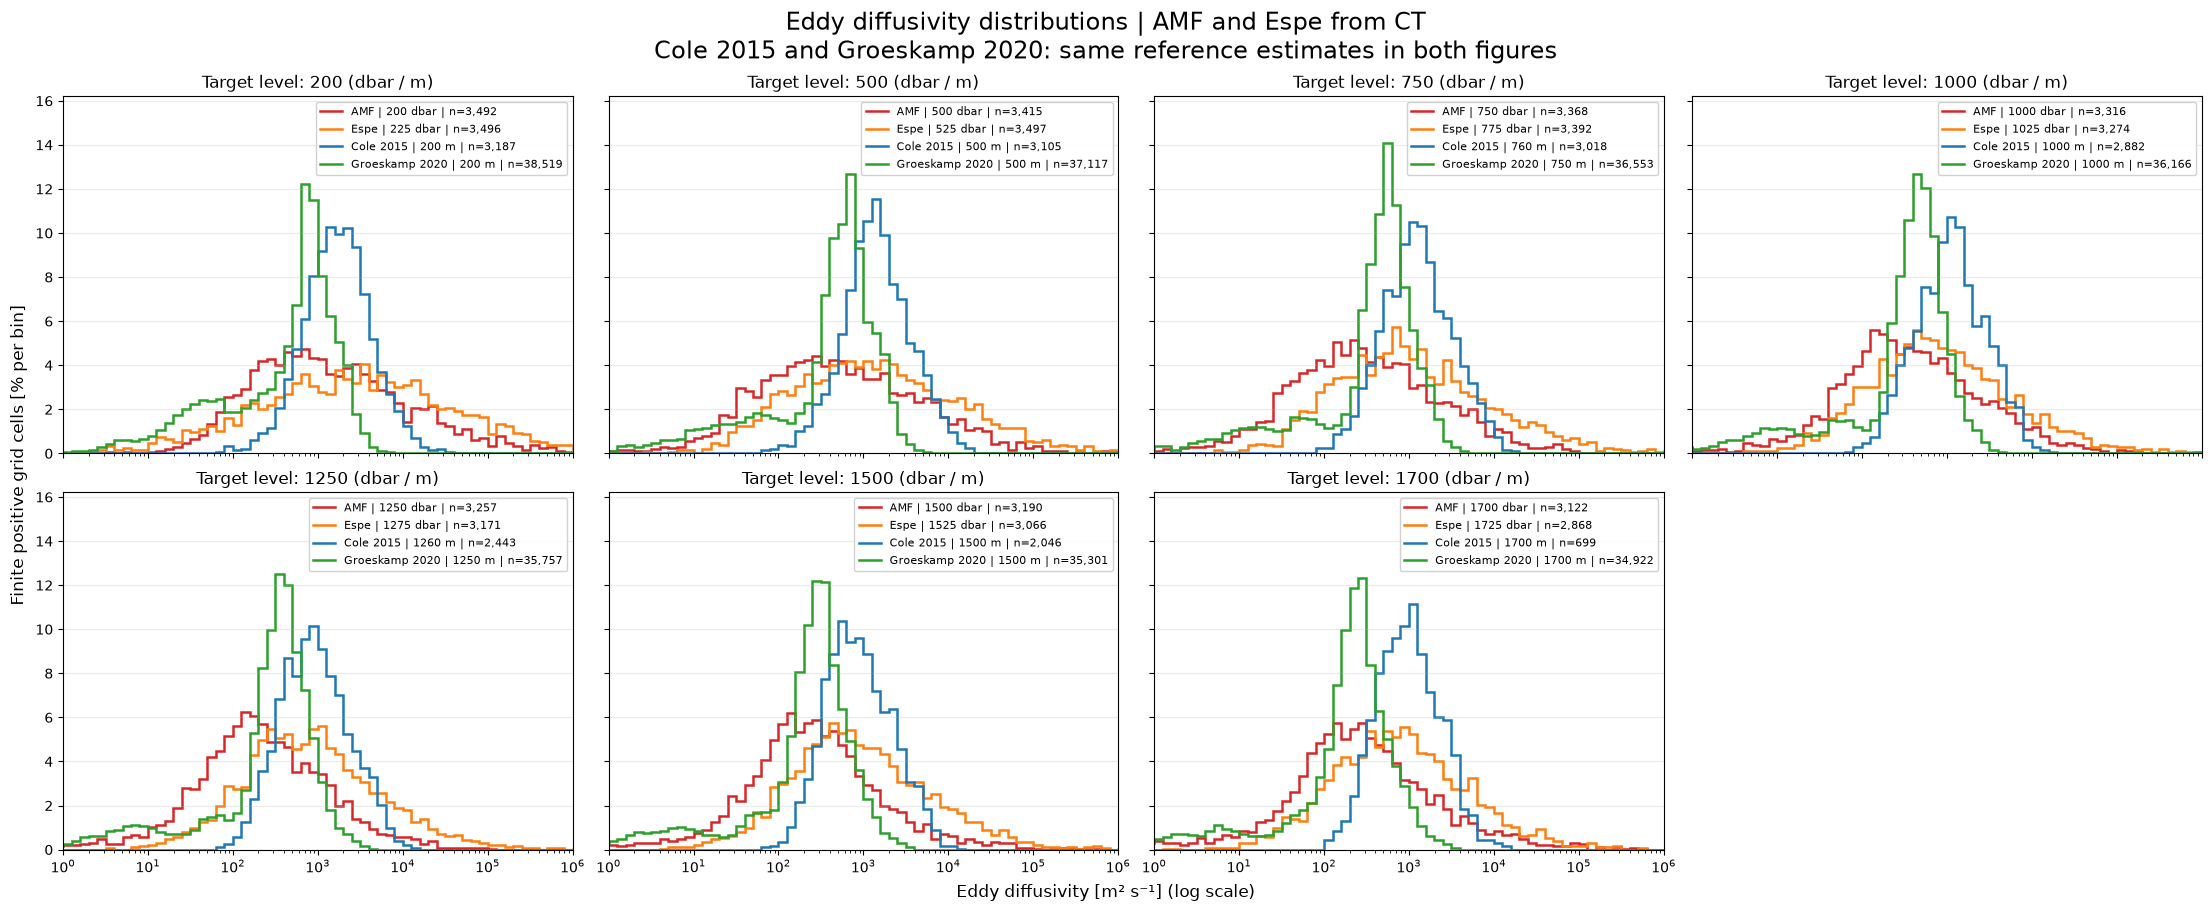

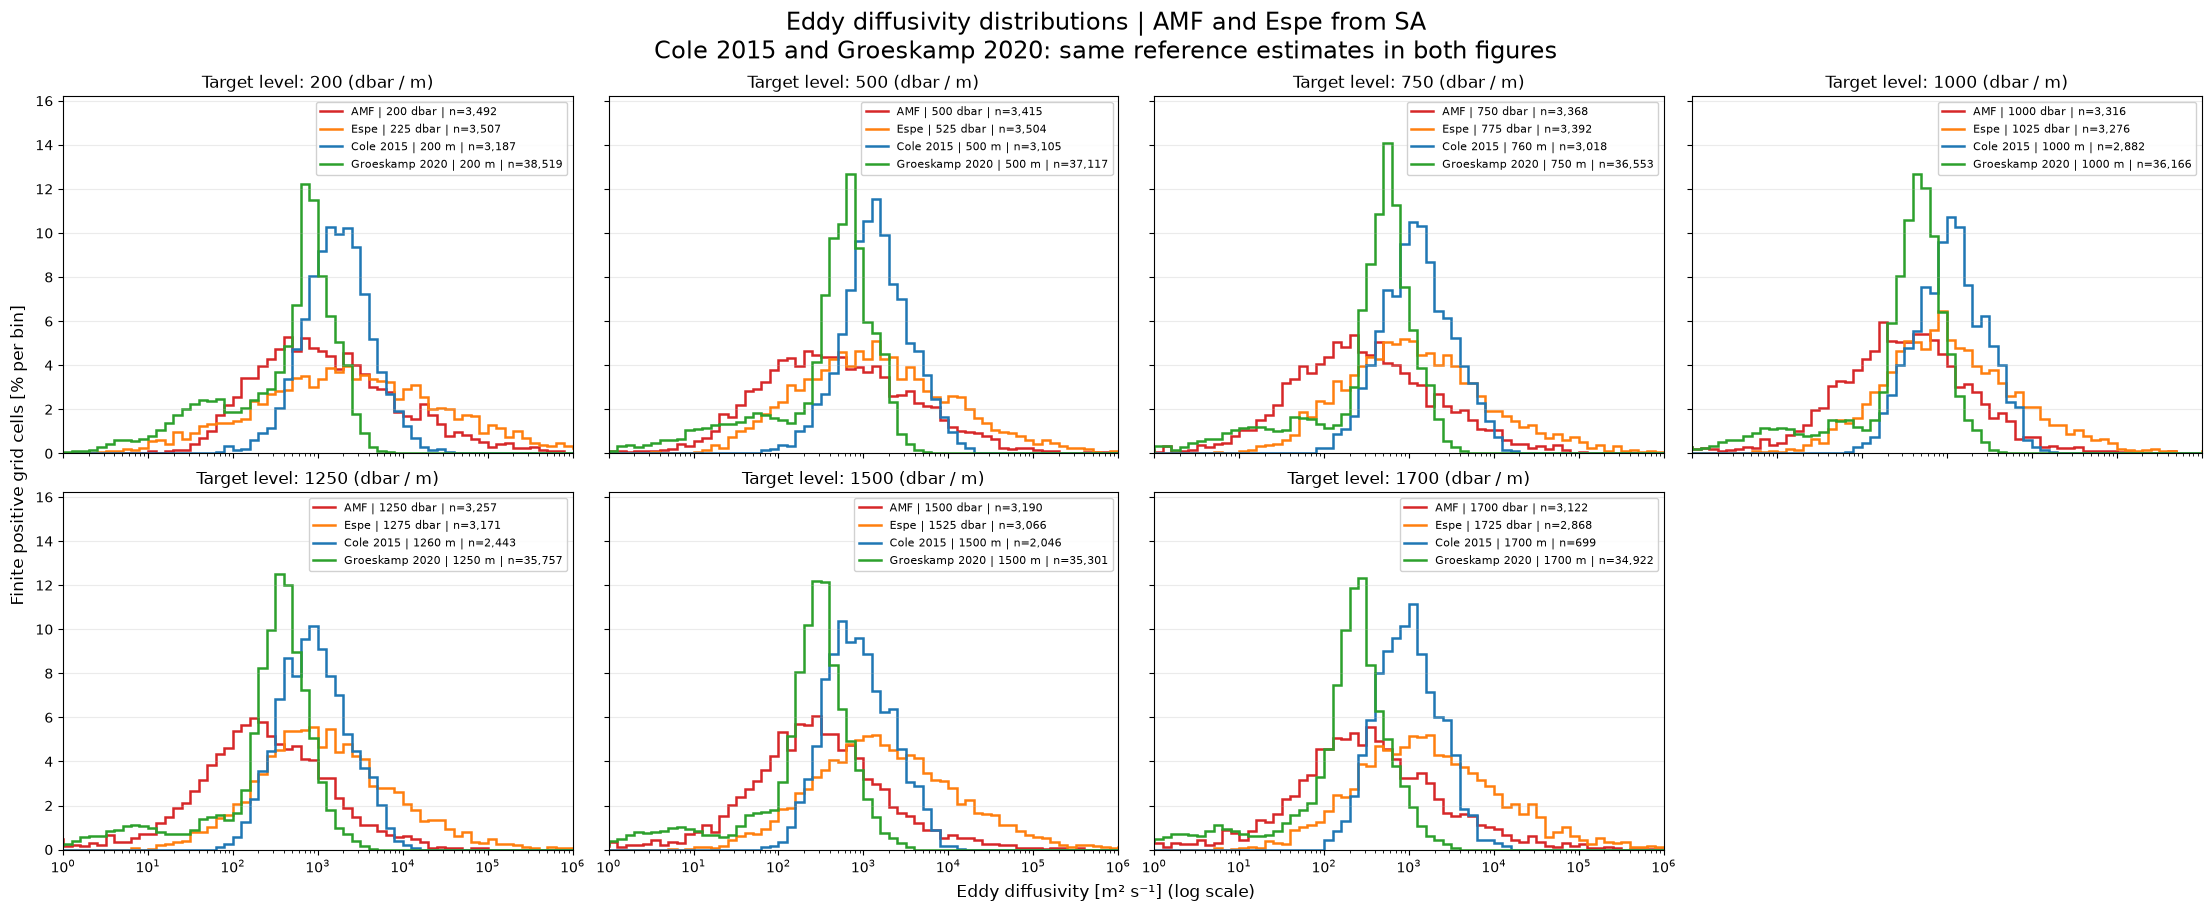

In [46]:
# Overlay the four studies at each depth; retain the figures for export.
for previous_figure in globals().get('histogram_figures', {}).values():
    plt.close(previous_figure)
histogram_figures = {}
histogram_axes = {}
histogram_percentages = {}

for tracer, xlimits in [('CT', CT_HISTOGRAM_XLIM), ('SA', SA_HISTOGRAM_XLIM)]:
    if not (np.all(np.isfinite(xlimits)) and 0 < xlimits[0] < xlimits[1]):
        raise ValueError(f'{tracer} histogram x-limits must be finite and satisfy 0 < minimum < maximum.')
    ncols = 4
    nrows = int(np.ceil(len(histogram_depths) / ncols))
    fig, axes = plt.subplots(
        nrows, ncols, figsize=(22, 4.5 * nrows), squeeze=False,
        sharex=True, sharey=True, constrained_layout=True,
    )
    fig.suptitle(
        f'Eddy diffusivity distributions | AMF and Espe from {tracer}\n'
        'Cole 2015 and Groeskamp 2020: same reference estimates in both figures',
        fontsize=17,
    )
    for ax, depth in zip(axes.flat, histogram_depths):
        for study, color in HISTOGRAM_COLORS.items():
            sample = histogram_samples[tracer, study, depth]
            values = sample['values']
            label = f"{study} | {sample['level']:g} {sample['unit']}"
            if values.size:
                counts, _ = np.histogram(values, bins=histogram_bins)
                percentages = 100 * counts / values.size
                histogram_percentages[tracer, study, depth] = percentages
                ax.stairs(
                    percentages, histogram_bins, color=color, linewidth=1.8,
                    label=f'{label} | n={values.size:,}',
                )
            else:
                # A legend entry records missing data without drawing a zero curve.
                ax.plot([], [], color=color, linewidth=1.8,
                        label=f'{label} | no positive data (n=0)')
        ax.set_title(f'Target level: {depth:g} (dbar / m)', fontsize=12)
        ax.set_xscale('log')
        ax.set_xlim(*xlimits)
        ax.set_ylim(bottom=0)
        ax.grid(axis='y', alpha=0.25)
        ax.legend(loc='upper right', fontsize=8, framealpha=0.9)
    for ax in list(axes.flat)[len(histogram_depths):]:
        ax.set_visible(False)
    fig.supxlabel('Eddy diffusivity [m² s⁻¹] (log scale)', fontsize=12)
    fig.supylabel('Finite positive grid cells [% per bin]', fontsize=12)
    histogram_figures[tracer] = fig
    histogram_axes[tracer] = axes

# One y-axis scale across both tracers and all displayed levels.
histogram_ymax = 1.15 * max(values.max() for values in histogram_percentages.values())
for axes in histogram_axes.values():
    for ax in axes.flat:
        ax.set_ylim(0, histogram_ymax)
plt.show()